# Online Retail: solución de la plantilla por línea de venta

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Archivo de clase y alcance
Se utiliza el CSV de clase de **12,786 filas**, conservado con su huella en el manifiesto.
Su estructura corresponde a [Online Retail de UCI (DOI 10.24432/C5BW33)](https://archive.ics.uci.edu/dataset/352/online+retail).
El dataset original tiene 541,909 filas; **este archivo es un recorte de clase**, no el dataset completo.
La procedencia inmediata del CSV es el material de referencia del curso; no se afirma una selección aleatoria.
La ventana del recorte se calcula abajo. Los resultados solo describen esas compras, no un año comercial completo.

In [2]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
datos = pd.read_csv(U3 / "data/raw/online_retail.csv", dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"})
print("Dimensiones:", datos.shape)
display(datos.head())
display(datos.isna().sum().to_frame("faltantes"))
print("Duplicados exactos:", datos.duplicated().sum())

Dimensiones: (12786, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


,faltantes
InvoiceNo,0
StockCode,0
Description,45
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,3506
Country,1


Duplicados exactos: 244


## 2. Limpieza y variables calculadas
Se aplican criterios transparentes y se registra la cantidad de filas tras cada filtro.
En esta plantilla se exige además `UnitPrice >= 1`, como convención del ejercicio;
no se afirma que un precio menor sea un error comercial. Se segmentan líneas, no clientes.

In [3]:
auditoria = [{"paso": "Archivo original", "filas": len(datos)}]
ventas = datos.drop_duplicates().copy()
auditoria.append({"paso": "Sin duplicados exactos", "filas": len(ventas)})
ventas["Quantity"] = pd.to_numeric(ventas.Quantity, errors="coerce")
ventas["UnitPrice"] = pd.to_numeric(ventas.UnitPrice, errors="coerce")
ventas["InvoiceDate"] = pd.to_datetime(ventas.InvoiceDate, errors="coerce", format="mixed", dayfirst=False)
ventas["InvoiceNo"] = ventas.InvoiceNo.str.strip().str.upper()
validos = ventas.CustomerID.notna() & ventas.InvoiceNo.notna() & ventas.InvoiceDate.notna()
ventas = ventas.loc[validos].copy()
auditoria.append({"paso": "Cliente, factura y fecha disponibles", "filas": len(ventas)})
ventas = ventas.loc[~ventas.InvoiceNo.str.startswith("C", na=False)].copy()
auditoria.append({"paso": "Sin facturas canceladas", "filas": len(ventas)})
ventas = ventas.loc[ventas.Quantity.gt(0) & ventas.UnitPrice.gt(0)].copy()
auditoria.append({"paso": "Cantidad y precio positivos", "filas": len(ventas)})
ventas["monto_linea"] = ventas.Quantity * ventas.UnitPrice
assert np.isfinite(ventas[["Quantity", "UnitPrice", "monto_linea"]].to_numpy()).all()
display(pd.DataFrame(auditoria))
print("Ventana observada:", ventas.InvoiceDate.min(), "a", ventas.InvoiceDate.max())

,paso,filas
0,Archivo original,12786
1,Sin duplicados exactos,12542
2,"Cliente, factura y fecha disponibles",9036
3,Sin facturas canceladas,8926
4,Cantidad y precio positivos,8925


Ventana observada: 2010-12-01 08:26:00 a 2010-12-06 14:08:00


In [4]:
ventas = ventas.loc[ventas.UnitPrice.ge(1)].copy()
auditoria.append({"paso": "Precio al menos 1 (criterio de la plantilla)", "filas": len(ventas)})
ventas["fecha"] = ventas.InvoiceDate.dt.strftime("%Y-%m-%d")
ventas["hora"] = ventas.InvoiceDate.dt.strftime("%H:%M:%S")
display(pd.DataFrame(auditoria))
display(ventas[["InvoiceNo", "Quantity", "UnitPrice", "monto_linea", "fecha", "hora"]].head())
guardar_tabla(ventas, "online_retail_limpios.csv")

,paso,filas
0,Archivo original,12786
1,Sin duplicados exactos,12542
2,"Cliente, factura y fecha disponibles",9036
3,Sin facturas canceladas,8926
4,Cantidad y precio positivos,8925
5,Precio al menos 1 (criterio de la plantilla),7256


,InvoiceNo,Quantity,UnitPrice,monto_linea,fecha,hora
0,536365,6.0,2.55,15.30,2010-12-01,08:26:00
1,536365,6.0,3.39,20.34,2010-12-01,08:26:00
2,536365,8.0,2.75,22.00,2010-12-01,08:26:00
3,536365,6.0,3.39,20.34,2010-12-01,08:26:00
4,536365,6.0,3.39,20.34,2010-12-01,08:26:00


CSV guardado: U3_1_modelos_ml/data/processed/online_retail_limpios.csv (7,256 filas)


## 3. Selección, exploración y logaritmo natural
Las entradas son las columnas originales `Quantity` y `UnitPrice`. Como ambas son
positivas, se aplica `ln` y después StandardScaler. Ni el monto ni el identificador de
cliente entran al modelo. El logaritmo comprime extremos; no garantiza normalidad.

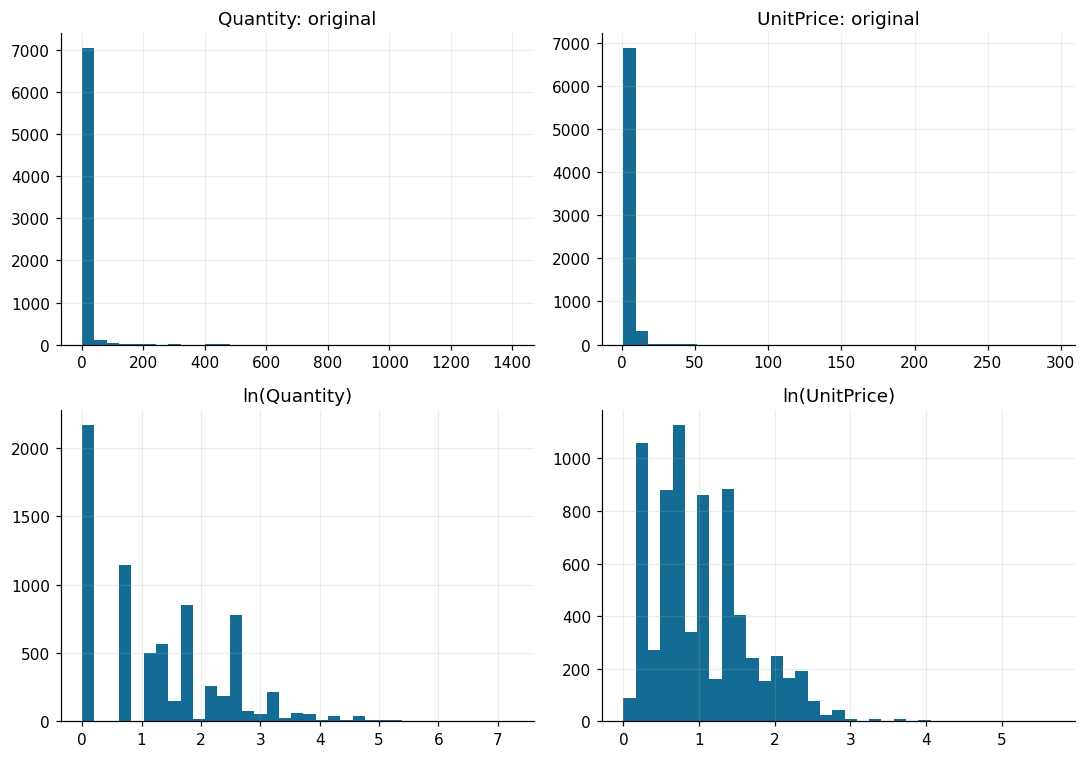

,variable,media_X,desviacion_X
0,Quantity,0.0,1.0
1,UnitPrice,-0.0,1.0


In [5]:
variables = ["Quantity", "UnitPrice"]
originales = ventas[variables].copy()
log_variables = np.log(originales)
escalador = StandardScaler()
X = escalador.fit_transform(log_variables)
assert np.isfinite(X).all()
fig, ejes = plt.subplots(2, 2, figsize=(10, 7))
for j, variable in enumerate(variables):
    ejes[0, j].hist(originales[variable], bins=35)
    ejes[0, j].set(title=f"{variable}: original")
    ejes[1, j].hist(log_variables[variable], bins=35)
    ejes[1, j].set(title=f"ln({variable})")
guardar_figura("U4_3_histogramas")
display(pd.DataFrame({"variable": variables, "media_X": X.mean(axis=0), "desviacion_X": X.std(axis=0)}).round(4))

## 4. Codo y silueta con una muestra fija
Cada candidato se ajusta con **todas** las líneas limpias. Para controlar el costo
cuadrático de la silueta se usa la misma muestra uniforme de hasta 2,000 líneas para todos
los k. Se informa que esa puntuación es una estimación; la inercia usa todas las filas.
El máximo de silueta entre 2 y 8 fija k, junto con la revisión de la curva y los perfiles.

,k,inercia,silueta_muestra
0,1,14512.0000,NaN
1,2,8528.9515,0.3745
2,3,5069.2611,0.4284
3,4,3921.5064,0.4207
4,5,3149.4598,0.4204
5,6,2455.5689,0.4270
6,7,2196.7539,0.4114
7,8,1963.9571,0.4224


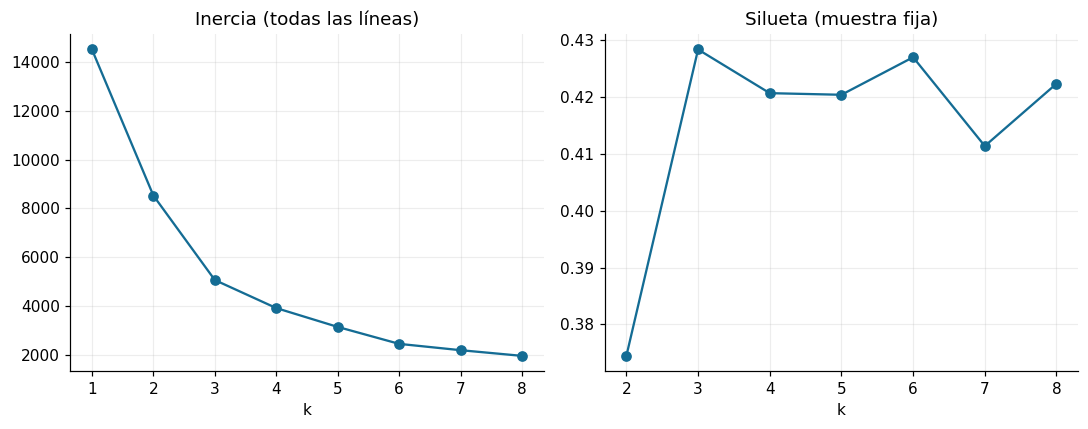

In [6]:
rng = np.random.default_rng(82005)
indices = rng.choice(len(X), size=min(2000, len(X)), replace=False)
filas = []
for k in range(1, 9):
    candidato = KMeans(n_clusters=k, n_init=20, random_state=82005)
    etiquetas = candidato.fit_predict(X)
    silueta = np.nan if k == 1 else silhouette_score(X[indices], etiquetas[indices])
    filas.append({"k": k, "inercia": candidato.inertia_, "silueta_muestra": silueta})
evaluacion = pd.DataFrame(filas)
display(evaluacion.round(4))
k_elegido = int(evaluacion.loc[evaluacion.silueta_muestra.idxmax(), "k"])
modelo = KMeans(n_clusters=k_elegido, n_init=20, random_state=82005)
ventas["grupo"] = modelo.fit_predict(X)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(evaluacion.k, evaluacion.inercia, "o-"); ejes[0].set(title="Inercia (todas las líneas)", xlabel="k")
ejes[1].plot(evaluacion.k, evaluacion.silueta_muestra, "o-"); ejes[1].set(title="Silueta (muestra fija)", xlabel="k")
guardar_figura("U4_3_eleccion_k")

## 5. Visualización y perfiles
Las coordenadas de la izquierda son las utilizadas por el modelo. A la derecha se
conservan las unidades originales con ejes logarítmicos. Se dibuja una muestra de hasta
3,000 líneas; el modelo y los perfiles utilizan todas las líneas limpias.

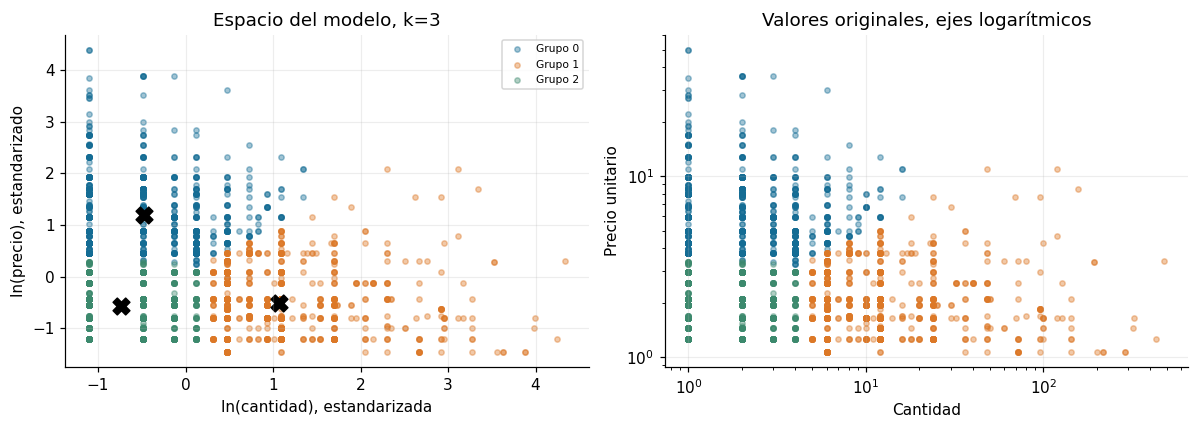

,lineas,cantidad_mediana,precio_mediano,cantidad_media,precio_medio,porcentaje_lineas
grupo,,,,,,
0,2248,2.0,5.95,2.62,7.07,30.98
1,2642,12.0,1.95,18.82,2.17,36.41
2,2366,1.0,1.95,1.72,2.01,32.61


CSV guardado: U3_1_modelos_ml/data/processed/retail_lineas_segmentadas.csv (7,256 filas)
CSV guardado: U3_1_modelos_ml/data/processed/retail_perfiles_lineas.csv (3 filas)
CSV guardado: U3_1_modelos_ml/data/processed/retail_lineas_eleccion_k.csv (8 filas)
CSV guardado: U3_1_modelos_ml/data/processed/retail_auditoria_lineas.csv (6 filas)


In [7]:
muestra = rng.choice(len(ventas), size=min(3000, len(ventas)), replace=False)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
etiquetas = ventas.grupo.to_numpy()
for grupo in sorted(ventas.grupo.unique()):
    seleccion = muestra[etiquetas[muestra] == grupo]
    ejes[0].scatter(X[seleccion, 0], X[seleccion, 1], s=12, alpha=.4, label=f"Grupo {grupo}")
    ejes[1].scatter(ventas.iloc[seleccion].Quantity, ventas.iloc[seleccion].UnitPrice, s=12, alpha=.4)
ejes[0].scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], color="black", marker="X", s=120)
ejes[0].set(xlabel="ln(cantidad), estandarizada", ylabel="ln(precio), estandarizado", title=f"Espacio del modelo, k={k_elegido}")
ejes[0].legend(fontsize=7)
ejes[1].set(xscale="log", yscale="log", xlabel="Cantidad", ylabel="Precio unitario", title="Valores originales, ejes logarítmicos")
guardar_figura("U4_3_segmentos")
perfiles = ventas.groupby("grupo").agg(lineas=("InvoiceNo", "size"),
    cantidad_mediana=("Quantity", "median"), precio_mediano=("UnitPrice", "median"),
    cantidad_media=("Quantity", "mean"), precio_medio=("UnitPrice", "mean"))
perfiles["porcentaje_lineas"] = 100*perfiles.lineas/len(ventas)
display(perfiles.round(2))
guardar_tabla(ventas, "retail_lineas_segmentadas.csv")
guardar_tabla(perfiles.reset_index(), "retail_perfiles_lineas.csv")
guardar_tabla(evaluacion, "retail_lineas_eleccion_k.csv")
guardar_tabla(pd.DataFrame(auditoria), "retail_auditoria_lineas.csv")

## 6. Actividades resueltas
**1. ¿Qué representa una fila?** Un producto en una línea de factura. Una persona puede
aparecer en grupos distintos porque compra productos diferentes; los grupos no describen clientes.

**2. ¿Qué cambia con ln y StandardScaler?** El logaritmo reduce la influencia de importes
extremos y el escalado iguala la dispersión de las dos coordenadas. Se mantienen dos variables.

**3. ¿Qué k elegir y qué aporta el codo?** La tabla siguiente informa las tres siluetas más
altas y la reducción relativa de inercia. Se elige la mayor silueta de la muestra fija; el codo
orienta sobre el detalle adicional, sin garantizar un número verdadero de grupos.

**4. ¿Precio alto significa rentabilidad alta?** No. Faltan costos, descuentos, devoluciones
y margen. `Quantity * UnitPrice` es importe bruto de la línea, no utilidad.

In [8]:
evaluacion["reduccion_inercia_pct"] = 100*(1-evaluacion.inercia/evaluacion.inercia.shift())
display(evaluacion.nlargest(3, "silueta_muestra").round(4))
display(evaluacion[["k", "reduccion_inercia_pct"]].round(2))
ganador = evaluacion.loc[evaluacion.k.eq(k_elegido)].iloc[0]
display(Markdown(f"Se elige **k={k_elegido}**, con silueta estimada **{ganador.silueta_muestra:.3f}**, "
                 f"sobre **{len(ventas):,} líneas** limpias. La muestra de silueta contiene {len(indices)} filas."))
for grupo, fila in perfiles.iterrows():
    display(Markdown(f"**Grupo {grupo}:** {fila.porcentaje_lineas:.1f}% de líneas; "
        f"mediana de {fila.cantidad_mediana:g} unidades a precio {fila.precio_mediano:.2f}."))

,k,inercia,silueta_muestra,reduccion_inercia_pct
2,3,5069.2611,0.4284,40.5641
5,6,2455.5689,0.4270,22.0321
7,8,1963.9571,0.4224,10.5973


,k,reduccion_inercia_pct
0,1,NaN
1,2,41.23
2,3,40.56
3,4,22.64
4,5,19.69
5,6,22.03
6,7,10.54
7,8,10.60


Se elige **k=3**, con silueta estimada **0.428**, sobre **7,256 líneas** limpias. La muestra de silueta contiene 2000 filas.

**Grupo 0:** 31.0% de líneas; mediana de 2 unidades a precio 5.95.

**Grupo 1:** 36.4% de líneas; mediana de 12 unidades a precio 1.95.

**Grupo 2:** 32.6% de líneas; mediana de 1 unidades a precio 1.95.

## 7. Conclusión
Los perfiles describen combinaciones de cantidad y precio en el recorte. Pueden orientar
una exploración de ventas por volumen o surtido, pero no identifican intención de compra,
fidelidad ni rentabilidad. Los porcentajes cuentan líneas, no clientes, facturas o ingresos.
Las decisiones de limpieza y la muestra de silueta forman parte del resultado y se documentan.
[Referencia de K-Means](https://scikit-learn.org/stable/modules/clustering.html#k-means).